# Lab 8 — Experiment notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab08.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click -> Save image as..., or `plt.savefig('fig1.png', dpi=150)`).
Report figures 1-3 are required by the report template.


In [1]:
import sys
sys.path.insert(0, '../src')
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import lab08

X, y, groups = lab08.load_data('../data/delivery_late.csv')
data = (X, y, groups)

table = lab08.run_ablation(lab08.BASE_CONFIG, lab08.FACTORS, lab08.SEEDS, data=data)
ablation = table.groupby('variant', sort=False)['f1'].agg(['mean', 'std']).round(4)

y_val, y_pred, groups_val = lab08.base_predictions(lab08.SEED)
errors = lab08.error_analysis(y_val, y_pred, groups_val)

records = [lab08.run_config(cfg, seed, data=data)
           for cfg in (lab08.BASE_CONFIG, lab08.CHALLENGER_CONFIG)
           for seed in lab08.SEEDS]
ranking = lab08.summarize(records)
ablation


,mean,std
variant,,
base,0.6439,0.0230
features=with_region,0.7355,0.0270
features=core,0.4741,0.0302
model=tree,0.5292,0.0431
class_weight=balanced,0.6787,0.0180
scale=False,0.6358,0.0210


## Plot 1 — Overall accuracy against per-slice accuracy

The point of the figure is the distance between the overall line and the worst bar, and the
sample count printed on each bar. A slice with fewer than 30 samples is not evidence.


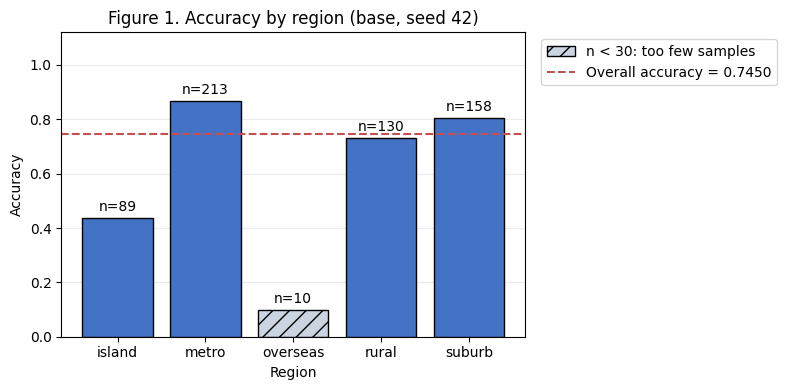

In [2]:
# ============ TODO (Plot 1) ============
# Bar chart of accuracy per slice from `errors["slices"]`, one bar per region.
# Draw the overall accuracy as a horizontal line, and print n on top of each bar.
# Mark (hatch, or a lighter colour) the slices with n < 30.
# =======================================

# [1] 지역별 accuracy와 표본 수를 꺼낸다.
regions = list(errors["slices"])
accuracy = [errors["slices"][r]["accuracy"] for r in regions]
counts = [errors["slices"][r]["n"] for r in regions]

# [2] 지역별 accuracy를 막대그래프로 그린다.
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    regions,
    accuracy,
    color="#4472C4",
    edgecolor="black",
)

# [3] n < 30인 지역을 구분하고 각 막대 위에 n을 표시한다.
small_label_added = False

for bar, n in zip(bars, counts):
    if n < 30:
        bar.set_facecolor("#CBD5E1")
        bar.set_hatch("//")

        if not small_label_added:
            bar.set_label("n < 30: too few samples")
            small_label_added = True

    ax.annotate(
        f"n={n}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
    )

# [4] 전체 accuracy를 수평 점선으로 표시한다.
overall = errors["overall"]["accuracy"]

ax.axhline(
    overall,
    color="#C44E52",
    linestyle="--",
    label=f"Overall accuracy = {overall:.4f}",
)

# [5] 제목, 축, 격자와 범례를 설정한다.
ax.set(
    xlabel="Region",
    ylabel="Accuracy",
    ylim=(0, 1.12),
    title="Figure 1. Accuracy by region (base, seed 42)",
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

# [6] 파일로 저장한 뒤 화면에 표시한다.
fig.tight_layout()
fig.savefig("fig1.png", dpi=300, bbox_inches="tight")
plt.show()


## Plot 2 — Ablation: which factors clear the seed noise

Each variant differs from the base in exactly one factor. The error bar is one sample standard
deviation over `lab08.SEEDS`. A bar whose error bar reaches the base band has not been shown to
do anything.


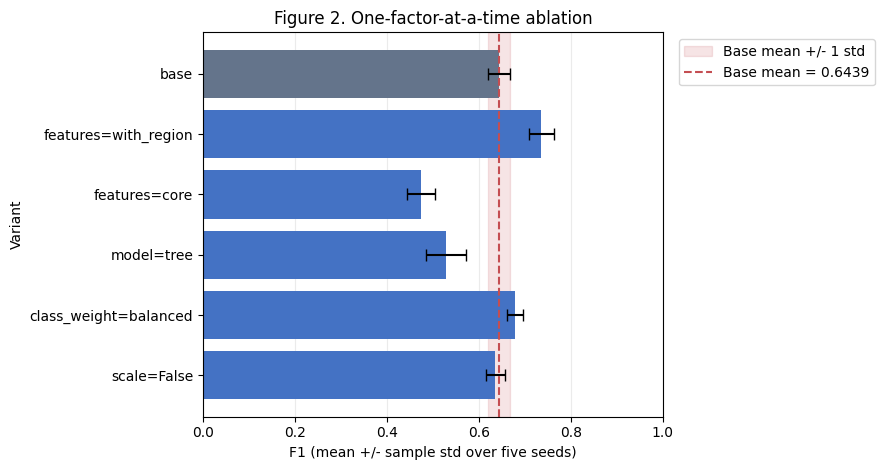

In [3]:
# ============ TODO (Plot 2) ============
# Horizontal bar chart of mean F1 per variant from `ablation`, with +-1 std error bars.
# Draw the base mean as a vertical line and its +-1 std as a shaded band.
# =======================================
# [1] base 평균과 표본 표준편차를 꺼낸다.
base_mean = float(ablation.loc["base", "mean"])
base_std = float(ablation.loc["base", "std"])
positions = np.arange(len(ablation))

fig, ax = plt.subplots(figsize=(9, 4.8))

# [2] base의 평균 ±1 표준편차 구간을 배경에 표시한다.
ax.axvspan(
    base_mean - base_std,
    base_mean + base_std,
    color="#C44E52",
    alpha=0.15,
    label="Base mean +/- 1 std",
)

# [3] base 평균을 수직 점선으로 표시한다.
ax.axvline(
    base_mean,
    color="#C44E52",
    linestyle="--",
    label=f"Base mean = {base_mean:.4f}",
)

# [4] 평균 F1을 가로 막대, 표준편차를 오차 막대로 그린다.
colors = [
    "#64748B" if name == "base" else "#4472C4"
    for name in ablation.index
]

ax.barh(
    positions,
    ablation["mean"].to_numpy(),
    xerr=ablation["std"].to_numpy(),
    color=colors,
    ecolor="black",
    capsize=4,
)

# [5] 원래 variant 순서를 유지하고 base를 맨 위에 배치한다.
ax.set_yticks(positions, ablation.index.tolist())
ax.invert_yaxis()

ax.set(
    xlabel="F1 (mean +/- sample std over five seeds)",
    ylabel="Variant",
    xlim=(0, 1),
    title="Figure 2. One-factor-at-a-time ablation",
)

ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

# [6] 파일로 저장한 뒤 화면에 표시한다.
fig.tight_layout()
fig.savefig("fig2.png", dpi=300, bbox_inches="tight")
plt.show()


## Plot 3 — Seed spread of two configurations

Same data as `ranking`, but one point per seed instead of one number per configuration. If the
two clouds interleave, the ranking between them is not a result yet.


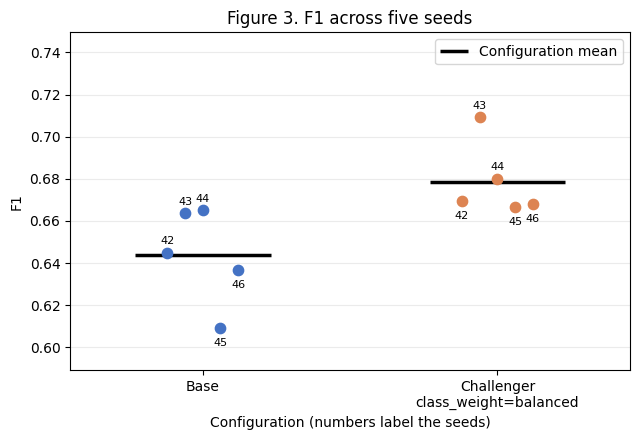

In [4]:
# ============ TODO (Plot 3) ============
# One point per (configuration, seed) for the base and the challenger, using `records`.
# Put the mean as a longer marker or a line. Label the axis with the metric name.
# =======================================

# [1] 비교 지표와 두 설정을 준비한다.
metric = "f1"
configs = [
    lab08.BASE_CONFIG,
    lab08.CHALLENGER_CONFIG,
]
colors = ["#4472C4", "#DD8452"]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
all_values = []

# [2] 각 설정의 record들을 찾아 seed 순서로 정렬한다.
for i, (config, color) in enumerate(zip(configs, colors)):
    cid = lab08.config_id(config)

    selected = sorted(
        [r for r in records if r["config_id"] == cid],
        key=lambda r: r["seed"],
    )

    values = np.array([
        r["metrics"][metric]
        for r in selected
    ])
    mean_value = values.mean()

    # [3] 점이 겹치지 않도록 가로 위치를 조금씩 나누어 표시한다.
    offsets = np.linspace(-0.12, 0.12, len(selected))
    x_positions = i + offsets

    ax.scatter(
        x_positions,
        values,
        color=color,
        s=55,
        zorder=3,
    )

    # [4] 각 점에 seed 번호를 표시한다.
    for x, value, record in zip(x_positions, values, selected):
        ax.annotate(
            str(record["seed"]),
            (x, value),
            xytext=(0, 6 if value >= mean_value else -13),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )

    # [5] 해당 설정의 평균을 긴 검은 선으로 표시한다.
    ax.hlines(
        mean_value,
        i - 0.23,
        i + 0.23,
        color="black",
        linewidth=2.5,
        zorder=2,
        label="Configuration mean" if i == 0 else None,
    )

    all_values.extend(values)

# [6] seed 간 차이를 읽을 수 있도록 세로 범위를 설정한다.
pad = max(0.01, 0.2 * np.ptp(all_values))

ax.set_ylim(
    max(0, min(all_values) - pad),
    min(1, max(all_values) + 2 * pad),
)

ax.set_xticks(
    [0, 1],
    ["Base", "Challenger\nclass_weight=balanced"],
)

ax.set(
    xlim=(-0.45, 1.45),
    xlabel="Configuration (numbers label the seeds)",
    ylabel=metric.upper(),
    title="Figure 3. F1 across five seeds",
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend()

# [7] 파일로 저장한 뒤 화면에 표시한다.
fig.tight_layout()
fig.savefig("fig3.png", dpi=300, bbox_inches="tight")
plt.show()